# Разведочный анализ датасета Авито

Этот ноутбук описывает данные кейса и готовит файлы для ручной проверки разметки.

Ноутбук сравнивает два набора данных:

* обучающий набор `public-train-annotated.jsonl` содержит 10 000 объявлений, которые модель разметила автоматически, поэтому разметка может содержать ошибки;
* публичный тестовый набор `public-test-dataset.parquet` содержит 208 объявлений, и организаторы называют его разметку эталоном.

Исходная микрокатегория у всех объявлений равна 101 «Ремонт под ключ», поэтому ноутбук анализирует только целевые микрокатегории от 102 до 106.

Чтобы запустить ноутбук, положите файлы данных в папку `data/raw` в корне репозитория и выполните все ячейки по порядку. Ноутбук сохраняет файлы для ручной проверки в папку `dataset_review/review`, а обработанные данные сохраняет в папку `data/processed`.

## 1. Подключаем библиотеки и задаём константы

Этот блок задаёт пути к данным и таблицу микрокатегорий. Словарь `CATEGORIES` сопоставляет идентификатор микрокатегории с её названием, а словарь `NAME_TO_ID` выполняет обратное сопоставление, потому что тестовый набор хранит названия вместо идентификаторов.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

pd.set_option("display.max_colwidth", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
REVIEW_DIR = Path("review")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REVIEW_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = {
    102: "Штукатурные работы",
    103: "Плиточные работы",
    104: "Сантехника",
    105: "Электрика",
    106: "Поклейка обоев и малярные работы",
}
CATEGORY_IDS = list(CATEGORIES)
NAME_TO_ID = {name: mc_id for mc_id, name in CATEGORIES.items()}
PLOT_LABELS = {
    102: "102 Штукатурка",
    103: "103 Плитка",
    104: "104 Сантехника",
    105: "105 Электрика",
    106: "106 Обои и покраска",
}
RANDOM_STATE = 42

## 2. Загружаем данные и приводим метки к одному виду

Этот блок читает оба набора и создаёт в каждом колонку `labels` со списком идентификаторов микрокатегорий. У тестового набора нет идентификатора объявления, поэтому блок создаёт колонку `row_id` из номера строки. У обучающего набора колонка `row_id` совпадает с `item_id`.

Как интерпретировать вывод. Список неизвестных названий должен быть пустым. Если он не пустой, значит в тестовом наборе встречается название, которого нет в таблице микрокатегорий, и такие метки нужно обсудить с организаторами. Число расхождений между идентификатором и названием в обучающем наборе тоже должно быть равно нулю.

In [2]:
train = pd.read_json(DATA_DIR / "public-train-annotated.jsonl", lines=True)
test = pd.read_parquet(DATA_DIR / "public-test-dataset.parquet")

for frame in (train, test):
    frame["title"] = frame["title"].fillna("").astype(str)
    frame["description"] = frame["description"].fillna("").astype(str)

train["row_id"] = train["item_id"]
test["row_id"] = np.arange(len(test))

train["labels"] = train["found_microcategories"].apply(
    lambda items: sorted({item["mcId"] for item in items})
)
test["labels"] = test["categories"].apply(
    lambda names: sorted({NAME_TO_ID[name] for name in names if name in NAME_TO_ID})
)

unknown_test_names = sorted(
    {name for names in test["categories"] for name in names} - set(NAME_TO_ID)
)
train_name_mismatches = sum(
    CATEGORIES.get(item["mcId"]) != item["label"]
    for items in train["found_microcategories"]
    for item in items
)
train_repeated_ids = sum(
    len(items) != len({item["mcId"] for item in items})
    for items in train["found_microcategories"]
)

print("Размер обучающего набора:", train.shape)
print("Размер тестового набора:", test.shape)
print("Неизвестные названия в тестовом наборе:", unknown_test_names)
print("Расхождения между идентификатором и названием в обучающем наборе:", train_name_mismatches)
print("Объявления с повтором одной микрокатегории в обучающем наборе:", train_repeated_ids)

Размер обучающего набора: (10000, 6)
Размер тестового набора: (208, 5)
Неизвестные названия в тестовом наборе: []
Расхождения между идентификатором и названием в обучающем наборе: 0
Объявления с повтором одной микрокатегории в обучающем наборе: 0


## 3. Проверяем базовое качество данных

Функция `basic_quality` считает пустые и очень короткие тексты, дубликаты идентификаторов и полные дубликаты описаний. Порог короткого текста равен 100 символам, потому что в таком тексте почти никогда не помещается перечень услуг.

Как интерпретировать вывод. Пустые и короткие описания не дают модели оснований для черновиков, поэтому их метки нужно проверить вручную. Большое число дубликатов описаний означает, что случайное разбиение на обучение и валидацию завысит качество, потому что одинаковые тексты попадут в обе части.

In [3]:
def basic_quality(frame):
    lengths = frame["description"].str.len()
    return pd.Series({
        "число строк": len(frame),
        "пустых описаний": int((lengths == 0).sum()),
        "описаний короче 100 символов": int((lengths < 100).sum()),
        "дубликатов идентификатора": int(frame["row_id"].duplicated().sum()),
        "полных дубликатов описания": int(frame["description"].duplicated().sum()),
        "полных дубликатов заголовка и описания": int(frame[["title", "description"]].duplicated().sum()),
    })


display(pd.DataFrame({"обучающий": basic_quality(train), "тестовый": basic_quality(test)}))
display(train.loc[train["description"].str.len() < 100, ["row_id", "title", "description", "labels"]].head(15))
display(test.loc[test["description"].str.len() < 100, ["row_id", "title", "description", "labels"]])

,обучающий,тестовый
число строк,10000,208
пустых описаний,0,0
описаний короче 100 символов,492,21
дубликатов идентификатора,0,0
полных дубликатов описания,5134,69
полных дубликатов заголовка и описания,4998,68


,row_id,title,description,labels
47,2512321250382,Ремонт квартир под ключ,Ремонт любой сложности,[]
54,2519592500303,"Укладка плитки, керамагранита, компле",Ответственность и порядок.,[]
69,2511120250985,Ремонт квартир частично и под ключ,Ремонт частично и под ключ,[]
71,2505463501186,Ремонт и отделка квартир под ключ с гарантией,Внутренняя отделка квартир под ключ\nРемонт квартир,[]
100,2506561502452,Ремонт квартир под ключ,7777,[]
110,2510291500645,Формула пространства: перепланировка и отделка в едином стиле,Формула пространства: перепланировка и отделка в едином стиле,[]
132,2500450752963,Отделочные работы под ключ,Отделочные работы под ключ\nДомов\nКвартир\nКоммерческих помещений\nЭлектрика любой сложности,[105]
144,2141917750676,Ремонт,Ремонт балконов,[]
152,2503613751093,Отделочные работы плитка,"Отделочник, плиточник",[103]
182,2502689004326,Ремонт и отделка квартир,Ремонт любой сложности.\nВсе виды отделочных работ,[]


,row_id,title,description,labels
6,6,Мастер внутренних отделочных работ,"Внутренняя отделка, шпатлёвка, гипсокартон.",[102]
10,10,Маляр штукатур отделка,Подготовка к обоям.\nПодготовка к покраске.\nПокраска.\nЭлектрика под ключ.,"[105, 106]"
12,12,"Ремонт и отделка квартир, стройка","Работаю прилежно и на совесть. Сориентируюсь на месте, предложу варианты",[]
51,51,"Внутренняя отделка квартир, домов","Строительные работы, внутренняя отделка квартир , домов",[]
65,65,Ремонт под ключ / квартиры / дома / бригада,роаи,[]
73,73,Ремонт квартир под ключ без посредников,"Ремонт квартир, домов под ключ.",[]
78,78,Ремонт квартир под ключ без посредников частник,Звоните пишите,[]
79,79,Ремонт и строительство,Ремонт и дизайн,[]
82,82,Ремонт квартир под ключ с гарантией,ааипвиаимии,[]
86,86,Ремонт под ключ/ квартиры/ дома / гарантия,аоомриаотм,[]


## 4. Сравниваем распределение меток

Функция `to_matrix` превращает списки меток в бинарную матрицу. Строки матрицы соответствуют объявлениям, а столбцы соответствуют микрокатегориям от 102 до 106. Именно в таком виде организаторы считают метрику micro F1.

Таблица показывает долю объявлений с каждой микрокатегорией, долю объявлений без дополнительных черновиков и среднее число меток на объявление.

Как интерпретировать вывод. Если доли в обучающем и тестовом наборах сильно отличаются, значит автоматическая разметка понимает задачу иначе, чем эталон, или наборы взяты из разных источников. В этом случае порог классификатора нужно подбирать на тестовом наборе, а не на обучающем.

,обучающий,тестовый
102 Штукатурка,0.548,0.298
103 Плитка,0.507,0.173
104 Сантехника,0.458,0.312
105 Электрика,0.456,0.356
106 Обои и покраска,0.548,0.279
без черновиков,0.291,0.510
среднее число меток,2.518,1.418


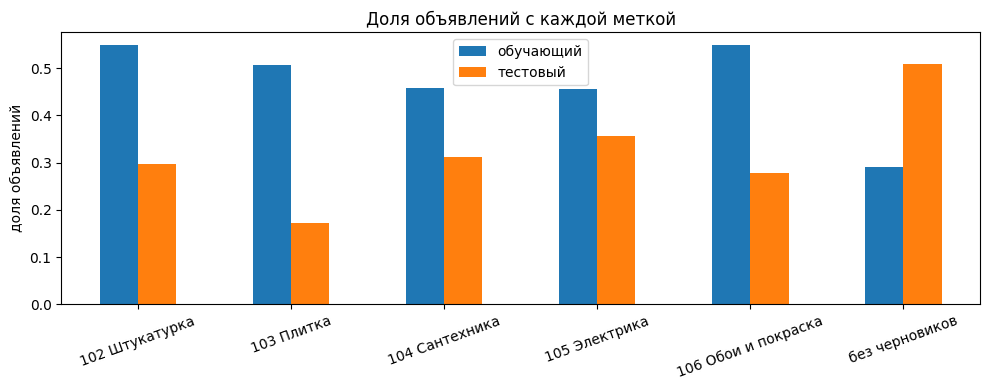

In [4]:
def to_matrix(label_lists):
    return np.array([[int(mc_id in labels) for mc_id in CATEGORY_IDS] for labels in label_lists])


Y_train = to_matrix(train["labels"])
Y_test = to_matrix(test["labels"])


def label_summary(matrix):
    summary = pd.Series(matrix.mean(axis=0), index=[PLOT_LABELS[mc_id] for mc_id in CATEGORY_IDS])
    summary["без черновиков"] = (matrix.sum(axis=1) == 0).mean()
    summary["среднее число меток"] = matrix.sum(axis=1).mean()
    return summary


distribution = pd.DataFrame({"обучающий": label_summary(Y_train), "тестовый": label_summary(Y_test)})
display(distribution.round(3))

ax = distribution.iloc[:6].plot.bar(figsize=(10, 4), rot=20)
ax.set_ylabel("доля объявлений")
ax.set_title("Доля объявлений с каждой меткой")
plt.tight_layout()
plt.show()

## 5. Смотрим, сколько меток получает одно объявление

Этот блок строит распределение числа меток на объявление в обоих наборах.

Как интерпретировать вывод. Пик на пяти метках в обучающем наборе означает, что автоматическая разметка часто отмечает все микрокатегории сразу. Если в тестовом наборе такого пика нет, то модель, обученная на обучающем наборе без поправок, будет давать много ложных срабатываний.

,обучающий,тестовый
0,0.291,0.510
1,0.096,0.091
2,0.108,0.149
3,0.132,0.062
4,0.056,0.096
5,0.317,0.091


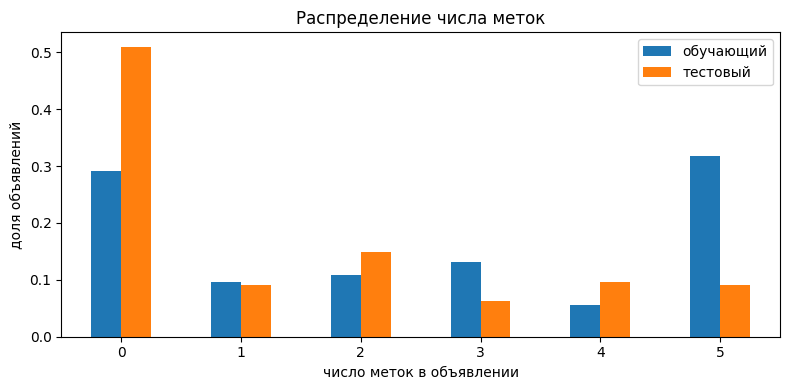

In [5]:
label_counts = pd.DataFrame({
    "обучающий": pd.Series(Y_train.sum(axis=1)).value_counts(normalize=True).sort_index(),
    "тестовый": pd.Series(Y_test.sum(axis=1)).value_counts(normalize=True).sort_index(),
}).fillna(0)
display(label_counts.round(3))

ax = label_counts.plot.bar(figsize=(8, 4), rot=0)
ax.set_xlabel("число меток в объявлении")
ax.set_ylabel("доля объявлений")
ax.set_title("Распределение числа меток")
plt.tight_layout()
plt.show()

## 6. Изучаем совместную встречаемость меток

Функция `conditional_matrix` считает условную вероятность. Ячейка в строке A и столбце B показывает, какая доля объявлений с меткой A также имеет метку B. Диагональ всегда равна единице.

Как интерпретировать вывод. Высокие значения вне диагонали показывают пары услуг, которые исполнители обычно предлагают вместе. Например, если штукатурка почти всегда идёт вместе с малярными работами, то классификатору легко перепутать эти микрокатегории, и спорные случаи нужно искать именно в этой паре.

Обучающий набор


,102 Штукатурка,103 Плитка,104 Сантехника,105 Электрика,106 Обои и покраска
102 Штукатурка,1.00,0.80,0.68,0.69,0.87
103 Плитка,0.87,1.00,0.78,0.77,0.83
104 Сантехника,0.81,0.86,1.00,0.94,0.76
105 Электрика,0.83,0.85,0.95,1.00,0.79
106 Обои и покраска,0.87,0.77,0.64,0.65,1.00


Тестовый набор


,102 Штукатурка,103 Плитка,104 Сантехника,105 Электрика,106 Обои и покраска
102 Штукатурка,1.00,0.37,0.71,0.74,0.71
103 Плитка,0.64,1.00,0.72,0.75,0.75
104 Сантехника,0.68,0.40,1.00,1.00,0.57
105 Электрика,0.62,0.36,0.88,1.00,0.55
106 Обои и покраска,0.76,0.47,0.64,0.71,1.00


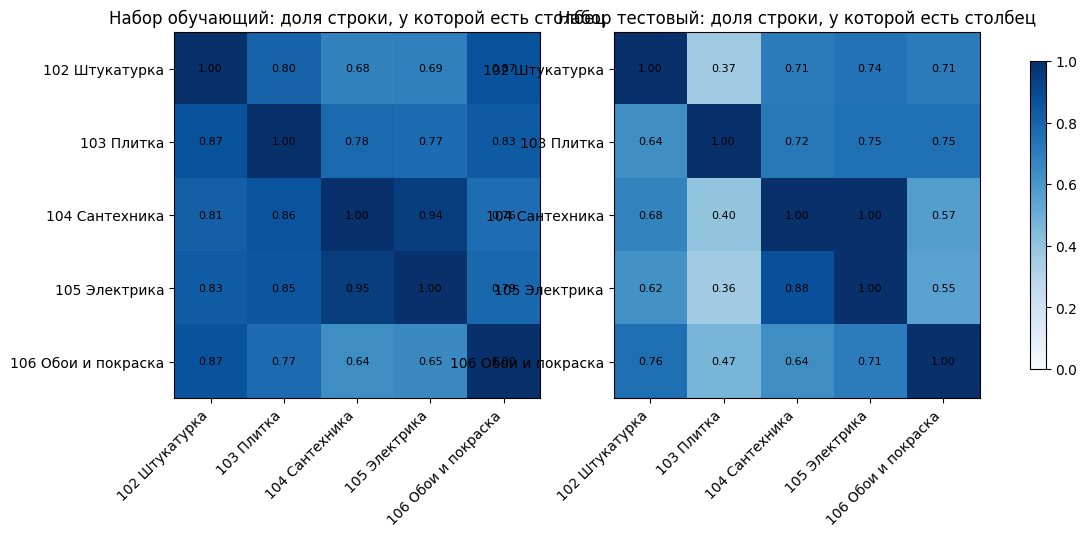

In [6]:
def conditional_matrix(matrix):
    counts = matrix.T @ matrix
    support = np.diag(counts).astype(float)
    support[support == 0] = np.nan
    labels = [PLOT_LABELS[mc_id] for mc_id in CATEGORY_IDS]
    return pd.DataFrame(counts / support[:, None], index=labels, columns=labels)


train_cooccurrence = conditional_matrix(Y_train)
test_cooccurrence = conditional_matrix(Y_test)
print("Обучающий набор")
display(train_cooccurrence.round(2))
print("Тестовый набор")
display(test_cooccurrence.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, frame, title in zip(axes, (train_cooccurrence, test_cooccurrence), ("обучающий", "тестовый")):
    image = ax.imshow(frame.values, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(5), frame.columns, rotation=45, ha="right")
    ax.set_yticks(range(5), frame.index)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{frame.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"Набор {title}: доля строки, у которой есть столбец")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

## 7. Оцениваем длину текстов

Этот блок считает длину описания в символах и словах, а затем показывает медианную длину для каждого числа меток.

Как интерпретировать вывод. Если длинные объявления получают заметно больше меток, то число меток во многом объясняется длиной перечня услуг. Если длина тестовых текстов похожа на длину обучающих, то наборы сопоставимы по формату. Самые длинные тексты важны для выбора модели, потому что они должны помещаться в контекст без обрезки.

,"обучающий, символы","тестовый, символы","обучающий, слова","тестовый, слова"
count,10000.0,208.0,10000.0,208.0
mean,2324.0,1627.0,331.0,228.0
std,1409.0,1237.0,198.0,170.0
min,1.0,4.0,1.0,1.0
25%,1385.0,575.0,198.0,77.0
50%,2196.0,1343.0,319.0,200.0
75%,3214.0,2808.0,463.0,386.0
max,5564.0,4480.0,818.0,616.0


,обучающий,тестовый
число меток,,
0,1797.0,784.0
1,1987.0,575.0
2,1460.0,2643.0
3,2484.0,3053.0
4,1568.0,1458.0
5,2675.0,2806.0


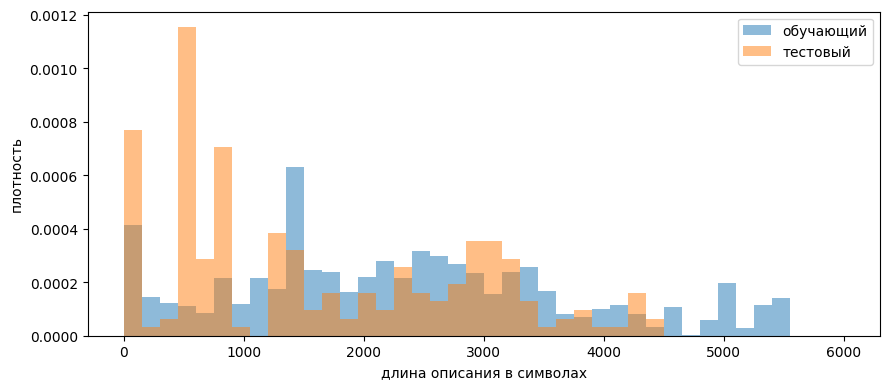

In [7]:
for frame in (train, test):
    frame["chars"] = frame["description"].str.len()
    frame["words"] = frame["description"].str.split().str.len()
    frame["n_labels"] = frame["labels"].str.len()

display(pd.DataFrame({
    "обучающий, символы": train["chars"].describe(),
    "тестовый, символы": test["chars"].describe(),
    "обучающий, слова": train["words"].describe(),
    "тестовый, слова": test["words"].describe(),
}).round(0))

display(pd.DataFrame({
    "обучающий": train.groupby("n_labels")["chars"].median(),
    "тестовый": test.groupby("n_labels")["chars"].median(),
}).rename_axis("число меток").round(0))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 6000, 41)
ax.hist(train["chars"], bins=bins, density=True, alpha=0.5, label="обучающий")
ax.hist(test["chars"], bins=bins, density=True, alpha=0.5, label="тестовый")
ax.set_xlabel("длина описания в символах")
ax.set_ylabel("плотность")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Ищем артефакты текста и нормализуем его

Функция `fix_homoglyphs` заменяет латинские буквы, похожие на кириллические, внутри слов, где смешаны оба алфавита. Авторы объявлений используют такую замену, чтобы обойти модерацию, например пишут «Peмонт» с латинской буквой P. Без этой замены поиск по словам и часть моделей не узнают слово.

Функция `normalize` применяет замену, переводит текст в нижний регистр и заменяет букву ё на е. Длина текста при этом не меняется, поэтому позиции найденных слов совпадают с позициями в исходном тексте.

Функция `find_seo_tail_start` ищет в конце объявления строку из многих коротких фраз через запятую. Авторы добавляют такой перечень для поиска на площадке, и он часто перечисляет услуги, которые исполнитель на самом деле не описывает в основном тексте.

Как интерпретировать вывод. Таблица показывает долю объявлений с каждым артефактом. Высокая доля смешанных алфавитов означает, что нормализация обязательна для любого решения. Высокая доля хвостов из ключевых слов означает, что команде нужно договориться, считать ли услугу из такого хвоста основанием для черновика.

In [8]:
HOMOGLYPHS = str.maketrans("aceopxyABCEHKMOPTXY", "асеорхуАВСЕНКМОРТХУ")
CYRILLIC_LETTER = re.compile(r"[а-яё]", re.IGNORECASE)
LATIN_LETTER = re.compile(r"[a-z]", re.IGNORECASE)
WORD = re.compile(r"\w+")
EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2B50\u2705]")
PHONE = re.compile(r"(?:\+7|\b8)[\s\-(]*\d{3}[\s\-)]*\d{3}[\s\-]*\d{2}[\s\-]*\d{2}")
LINK = re.compile(r"https?://|www\.|t\.me/|\.ru\b|\.рф\b", re.IGNORECASE)
CAPS_WORD = re.compile(r"\b[А-ЯЁ]{4,}\b")


def is_mixed_word(word):
    return bool(CYRILLIC_LETTER.search(word)) and bool(LATIN_LETTER.search(word))


def fix_homoglyphs(text):
    return WORD.sub(lambda match: match.group(0).translate(HOMOGLYPHS) if is_mixed_word(match.group(0)) else match.group(0), text)


def normalize(text):
    return fix_homoglyphs(text).lower().replace("ё", "е")


def find_seo_tail_start(text):
    stripped = text.rstrip()
    last_line = stripped.split("\n")[-1].strip()
    items = [item.strip() for item in last_line.split(",") if item.strip()]
    if len(items) >= 7 and np.mean([len(item) for item in items]) <= 40 and last_line.count(".") <= 1:
        return stripped.rfind(last_line)
    return len(text)


for frame in (train, test):
    frame["norm"] = frame["description"].map(normalize)
    frame["tail_start"] = frame["description"].map(find_seo_tail_start)
    frame["has_seo_tail"] = frame["tail_start"] < frame["description"].str.len()


def artifact_summary(frame):
    text = frame["description"]
    return pd.Series({
        "слова со смешанными алфавитами": text.map(lambda value: any(is_mixed_word(word) for word in WORD.findall(value))).mean(),
        "эмодзи": text.str.contains(EMOJI).mean(),
        "телефон": text.str.contains(PHONE).mean(),
        "ссылка": text.str.contains(LINK).mean(),
        "три и больше слов заглавными буквами": text.map(lambda value: len(CAPS_WORD.findall(value)) >= 3).mean(),
        "хвост из ключевых слов": frame["has_seo_tail"].mean(),
    })


display(pd.DataFrame({"обучающий": artifact_summary(train), "тестовый": artifact_summary(test)}).round(3))

mixed_examples = train["description"].map(lambda value: [word for word in WORD.findall(value) if is_mixed_word(word)][:8])
print("Примеры слов со смешанными алфавитами:")
print(mixed_examples[mixed_examples.str.len() > 0].head(5).tolist())
print()
print("Пример хвоста из ключевых слов:")
print(train.loc[train["has_seo_tail"], "description"].map(lambda value: value[find_seo_tail_start(value):][:400]).iloc[0])

,обучающий,тестовый
слова со смешанными алфавитами,0.055,0.062
эмодзи,0.837,0.683
телефон,0.000,0.000
ссылка,0.000,0.000
три и больше слов заглавными буквами,0.542,0.447
хвост из ключевых слов,0.208,0.072


Примеры слов со смешанными алфавитами:
[['PROквадраты'], ['мoнтаж'], ['Планируeте', 'cтpоительство', 'ремoнт', 'Нaпишите', 'нaм', 'пoможeм', 'вoплoтить', 'прoeкт'], ['АкимовPRO'], ['Cразу', 'скaжу', 'мелочёвкoй', 'зaнимaюсь', 'Tипа', 'НAПИШИТE', 'ПОЗВОHИТE']]

Пример хвоста из ключевых слов:
Ремонт квартир, ремонт квартиры под ключ, ремонт новостройки, ремонт вторички, частная бригада ремонт квартир, ремонт комнаты, ремонт кухни, ремонт санузла, ремонт ванной, ремонт коридора, черновая отделка квартиры, чистовая отделка квартиры, штукатурка стен, шпаклёвка стен, поклейка обоев, покраска стен, укладка плитки, укладка ламината, электрика в квартире, сантехника в квартире


## 9. Проверяем дубликаты и пересечение наборов

Этот блок группирует объявления по нормализованному описанию. Нормализация убирает разницу в регистре, в букве ё и в подменённых латинских буквах.

Блок считает четыре величины:

* сколько групп дубликатов есть в каждом наборе и насколько они большие;
* в скольких группах одинаковые тексты получили разные метки, что прямо указывает на шум разметки;
* сколько тестовых объявлений встречаются в обучающем наборе и совпадают ли у них метки;
* какой micro F1 на тестовом наборе получит даже идеальное решение, если в нём есть одинаковые тексты с разными метками.

Как интерпретировать вывод. Группы с разными метками нужно проверить вручную в первую очередь, потому что хотя бы одна метка в такой группе ошибочна. Решение получает на вход только текст, поэтому на одинаковые тексты оно всегда отвечает одинаково, и потолок micro F1 показывает, сколько качества теряется из-за противоречий в эталоне. Совпадение тестовых текстов с обучающими позволяет напрямую измерить, насколько автоматическая разметка согласуется с эталоном. Если пересечение большое, то эти тексты нужно убрать из обучения перед честной оценкой модели на тестовом наборе.

In [9]:
train["norm_key"] = train["norm"].str.split().str.join(" ")
test["norm_key"] = test["norm"].str.split().str.join(" ")
for frame in (train, test):
    frame["labels_key"] = frame["labels"].map(tuple)


def duplicate_report(frame, name):
    groups = frame.groupby("norm_key").agg(size=("row_id", "size"), label_variants=("labels_key", "nunique"))
    duplicate_groups = groups[groups["size"] > 1]
    conflict_keys = set(duplicate_groups.index[duplicate_groups["label_variants"] > 1])
    print(f"Набор {name}")
    print("  уникальных описаний:", len(groups), "из", len(frame))
    print("  групп дубликатов:", len(duplicate_groups))
    print("  объявлений внутри групп дубликатов:", int(duplicate_groups["size"].sum()))
    print("  групп дубликатов с разными метками:", len(conflict_keys))
    print("  объявлений внутри противоречивых групп:", int(frame["norm_key"].isin(conflict_keys).sum()))
    return conflict_keys


train_conflict_keys = duplicate_report(train, "обучающий")
test_conflict_keys = duplicate_report(test, "тестовый")


def majority_ceiling(frame, matrix):
    predictions = np.zeros_like(matrix)
    for _, positions in frame.groupby("norm_key").indices.items():
        predictions[positions] = (matrix[positions].mean(axis=0) >= 0.5).astype(int)
    return f1_score(matrix, predictions, average="micro")


print()
print("Потолок micro F1 на тестовом наборе для решения, которое видит только текст:", round(majority_ceiling(test, Y_test), 3))

test_conflicts = test[test["norm_key"].isin(test_conflict_keys)].sort_values(["norm_key", "row_id"])
print()
print("Примеры одинаковых тестовых текстов с разными метками:")
display(test_conflicts[["row_id", "title", "labels"]].head(20))

overlap = test.merge(
    train[["norm_key", "labels"]].rename(columns={"labels": "train_labels"}),
    on="norm_key",
    how="inner",
).drop_duplicates("row_id")
print("Тестовых объявлений, которые есть в обучающем наборе:", len(overlap), "из", len(test))
if len(overlap):
    overlap["same_labels"] = overlap["labels"].map(tuple) == overlap["train_labels"].map(tuple)
    print("Доля совпадающих меток у пересечения:", round(overlap["same_labels"].mean(), 3))
    print("micro F1 автоматической разметки относительно эталона на пересечении:",
          round(f1_score(to_matrix(overlap["labels"]), to_matrix(overlap["train_labels"]), average="micro", zero_division=0), 3))
    display(overlap.loc[~overlap["same_labels"], ["row_id", "title", "labels", "train_labels"]].head(20))

Набор обучающий
  уникальных описаний: 4826 из 10000
  групп дубликатов: 419
  объявлений внутри групп дубликатов: 5593
  групп дубликатов с разными метками: 0
  объявлений внутри противоречивых групп: 0
Набор тестовый
  уникальных описаний: 139 из 208
  групп дубликатов: 26
  объявлений внутри групп дубликатов: 95
  групп дубликатов с разными метками: 13
  объявлений внутри противоречивых групп: 56

Потолок micro F1 на тестовом наборе для решения, которое видит только текст: 0.924

Примеры одинаковых тестовых текстов с разными метками:


,row_id,title,labels
13,13,Ремонт и отделка квартир / Капитальный ремонт,"[103, 104, 105]"
58,58,Ремонт и отделка квартир / Капитальный ремонт,[]
40,40,Внутренняя отделка и ремонт квартир / домов,[]
160,160,Внутренняя отделка и ремонт квартир / домов,"[102, 103, 104, 105, 106]"
36,36,Ремонт дома. Подъем дома. Замена венцов,"[102, 103, 104, 105, 106]"
203,203,Ремонт дома. Подъем дома. Замена венцов,"[102, 104, 105, 106]"
94,94,Реконструкция домов. Ремонт домов. Замена венцов,"[102, 104, 105]"
151,151,Реконструкция домов. Ремонт домов. Замена венцов,"[102, 104, 105]"
161,161,Реконструкция домов. Ремонт домов. Замена венцов,"[104, 105]"
162,162,Реконструкция домов. Ремонт домов. Замена венцов,"[104, 105]"


Тестовых объявлений, которые есть в обучающем наборе: 24 из 208
Доля совпадающих меток у пересечения: 0.875
micro F1 автоматической разметки относительно эталона на пересечении: 0.961


,row_id,title,labels,train_labels
38,45,Ремонт домов. Замена венцов. Подъем дома,"[104, 105]","[102, 104, 105]"
307,178,Ремонт домов. Замена венцов. Подъем дома,"[104, 105]","[102, 104, 105]"
374,202,Ремонт домов. Замена венцов. Подъем дома,"[104, 105]","[102, 104, 105]"


## 10. Строим словарь ключевых слов и сравниваем его с разметкой

Словарь `KEYWORDS` содержит для каждой микрокатегории список регулярных выражений. Список составлен по справочнику микрокатегорий и намеренно остаётся простым. Он служит инструментом анализа, а не готовым решением.

Функция `find_hits` возвращает все совпадения в нормализованном тексте вместе с позицией. Функция `hit_matrix` превращает совпадения в бинарную матрицу того же вида, что и матрица меток.

Таблица согласия показывает для каждой микрокатегории две вероятности:

* доля объявлений с меткой среди объявлений, где нашлось ключевое слово;
* доля объявлений с ключевым словом среди объявлений с меткой.

Как интерпретировать вывод. Первая вероятность показывает, как часто разметка отказывается от черновика, хотя слово есть. Низкое значение говорит о том, что разметка учитывает контекст, например отрицания или упоминания в общем перечне. Вторая вероятность показывает полноту словаря. Низкое значение означает, что разметка находит услугу по словам, которых нет в словаре, и эти слова нужно найти в файле для ручной проверки. Значение micro F1 словаря задаёт нижнюю планку качества, которую любое решение должно превзойти.

In [10]:
KEYWORDS = {
    102: [r"штукатур\w*", r"оштукатур\w*", r"по маякам", r"маяк\w*", r"откос\w*"],
    103: [r"плитк\w*", r"плиточн\w*", r"кафел\w*", r"керамогранит\w*", r"мозаик\w*", r"фартук\w*"],
    104: [
        r"сантехн\w*", r"водоснабжени\w*", r"водопровод\w*", r"канализаци\w*", r"смесител\w*",
        r"унитаз\w*", r"раковин\w*", r"инсталляци\w*", r"полотенцесушител\w*", r"радиатор\w*",
        r"водонагревател\w*|бойлер\w*", r"засор\w*", r"(?:замен|разводк|прокладк|монтаж)\w* труб\w*",
        r"душев\w* кабин\w*",
    ],
    105: [
        r"электри\w*", r"электромонтаж\w*", r"электропроводк\w*|проводк\w*", r"розет\w*",
        r"выключател\w*", r"электрощит\w*|щиток\w*", r"светильник\w*|люстр\w*|освещени\w*",
        r"кабел\w*", r"узо\b|дифавтомат\w*",
    ],
    106: [
        r"\bобо(?:и|ев|ями|ям|ях)\b", r"поклейк\w*", r"маляр\w*", r"покраск\w*|окраск\w*|покрас\w*",
        r"шпакл\w*|шпатл\w*", r"стеклохолст\w*", r"грунтов\w*",
    ],
}
COMPILED = {mc_id: [re.compile(pattern) for pattern in patterns] for mc_id, patterns in KEYWORDS.items()}


def find_hits(norm_text):
    hits = {mc_id: [] for mc_id in CATEGORY_IDS}
    for mc_id, patterns in COMPILED.items():
        for pattern_index, pattern in enumerate(patterns):
            for match in pattern.finditer(norm_text):
                hits[mc_id].append((pattern_index, match.start(), match.end(), match.group(0)))
    return hits


def hit_matrix(hits_column):
    return np.array([[int(bool(hits[mc_id])) for mc_id in CATEGORY_IDS] for hits in hits_column])


for frame in (train, test):
    frame["hits"] = frame["norm"].map(find_hits)

H_train = hit_matrix(train["hits"])
H_test = hit_matrix(test["hits"])


def agreement_table(labels, hits):
    rows = {}
    for column, mc_id in enumerate(CATEGORY_IDS):
        label_column, hit_column = labels[:, column], hits[:, column]
        rows[PLOT_LABELS[mc_id]] = {
            "объявлений со словом": int(hit_column.sum()),
            "объявлений с меткой": int(label_column.sum()),
            "доля меток среди слов": label_column[hit_column == 1].mean() if hit_column.sum() else np.nan,
            "доля слов среди меток": hit_column[label_column == 1].mean() if label_column.sum() else np.nan,
            "F1 словаря": f1_score(label_column, hit_column, zero_division=0),
        }
    return pd.DataFrame(rows).T


print("Обучающий набор, micro F1 словаря:", round(f1_score(Y_train, H_train, average="micro"), 3))
display(agreement_table(Y_train, H_train).round(3))
print("Тестовый набор, micro F1 словаря:", round(f1_score(Y_test, H_test, average="micro"), 3))
display(agreement_table(Y_test, H_test).round(3))

Обучающий набор, micro F1 словаря: 0.927


,объявлений со словом,объявлений с меткой,доля меток среди слов,доля слов среди меток,F1 словаря
102 Штукатурка,5277.0,5484.0,0.833,0.801,0.817
103 Плитка,5472.0,5073.0,0.927,1.000,0.962
104 Сантехника,4930.0,4582.0,0.923,0.993,0.956
105 Электрика,4952.0,4562.0,0.920,0.999,0.958
106 Обои и покраска,5950.0,5481.0,0.910,0.988,0.948


Тестовый набор, micro F1 словаря: 0.817


,объявлений со словом,объявлений с меткой,доля меток среди слов,доля слов среди меток,F1 словаря
102 Штукатурка,68.0,62.0,0.647,0.71,0.677
103 Плитка,53.0,36.0,0.679,1.00,0.809
104 Сантехника,84.0,65.0,0.774,1.00,0.872
105 Электрика,98.0,74.0,0.755,1.00,0.860
106 Обои и покраска,80.0,58.0,0.725,1.00,0.841


### Сравниваем micro F1 и macro F1

Этот блок считает micro F1 и macro F1 для всех оценок качества в ноутбуке. Метрика micro F1 складывает ошибки по всем микрокатегориям, поэтому частые категории влияют на неё сильнее. Метрика macro F1 сначала считает F1 для каждой микрокатегории отдельно, а затем берёт среднее, поэтому все категории влияют на неё одинаково. Организаторы оценивают решения по micro F1, а macro F1 нужна для контроля.

Потолок для решения, которое видит только текст, блок считает так же, как в разделе 9: для каждой группы одинаковых тестовых текстов он выбирает метки большинства.

Как интерпретировать вывод. Если macro F1 заметно ниже micro F1, значит решение плохо работает на какой-то одной категории, и эту категорию можно найти в таблице согласия выше. Если обе метрики близки, значит качество распределено по категориям равномерно.

In [11]:
def majority_predictions(frame, matrix):
    predictions = np.zeros_like(matrix)
    for _, positions in frame.groupby("norm_key").indices.items():
        predictions[positions] = (matrix[positions].mean(axis=0) >= 0.5).astype(int)
    return predictions


evaluations = {
    "словарь против обучающей разметки": (Y_train, H_train),
    "словарь против эталона теста": (Y_test, H_test),
    "автоматическая разметка против эталона на пересечении": (to_matrix(overlap["labels"]), to_matrix(overlap["train_labels"])),
    "потолок на тесте для решения, которое видит только текст": (Y_test, majority_predictions(test, Y_test)),
}
display(pd.DataFrame({
    name: {
        "micro F1": f1_score(truth, prediction, average="micro", zero_division=0),
        "macro F1": f1_score(truth, prediction, average="macro", zero_division=0),
    }
    for name, (truth, prediction) in evaluations.items()
}).T.round(3))

,micro F1,macro F1
словарь против обучающей разметки,0.927,0.928
словарь против эталона теста,0.817,0.812
автоматическая разметка против эталона на пересечении,0.961,0.960
"потолок на тесте для решения, которое видит только текст",0.924,0.925


## 11. Проверяем, какие отдельные слова разметка считает достаточными

Этот блок берёт объявления, где у микрокатегории сработало ровно одно регулярное выражение, и считает долю таких объявлений с меткой. Так видно, какое слово само по себе разметка считает основанием для черновика.

Как интерпретировать вывод. Если у слова доля меток близка к единице, то разметка считает одно упоминание этого слова достаточным. Если доля близка к нулю, то разметка считает слово слабым признаком. Например, слово «откосы» может означать пластиковые откосы окон, а слово «освещение» может относиться к натяжным потолкам. Особенно важны строки, где доли в обучающем и тестовом наборах расходятся, потому что именно там автоматическая разметка понимает правила иначе, чем эталон.

In [12]:
def single_term_table(frame, matrix):
    records = []
    for column, mc_id in enumerate(CATEGORY_IDS):
        for hits, label in zip(frame["hits"], matrix[:, column]):
            patterns = {hit[0] for hit in hits[mc_id]}
            if len(patterns) == 1:
                records.append((PLOT_LABELS[mc_id], KEYWORDS[mc_id][patterns.pop()], label))
    table = pd.DataFrame(records, columns=["категория", "выражение", "метка"])
    return table.groupby(["категория", "выражение"])["метка"].agg(["count", "mean"])


single_terms = single_term_table(train, Y_train).join(
    single_term_table(test, Y_test), lsuffix=" обучающий", rsuffix=" тестовый", how="outer"
)
single_terms.columns = ["объявлений, обучающий", "доля меток, обучающий", "объявлений, тестовый", "доля меток, тестовый"]
display(single_terms.round(2))

объявлений, обучающий  доля меток, обучающий  объявлений, тестовый  доля меток, тестовый
категория           выражение                                                                                                                             
102 Штукатурка      откос\w*                                                        628                   0.19                   2.0                  0.00
                    штукатур\w*                                                    2802                   0.89                  52.0                  0.65
103 Плитка          кафел\w*                                                         79                   0.94                   NaN                   NaN
                    керамогранит\w*                                                  31                   0.97                   1.0                  1.00
                    плитк\w*                                                       1865                   0.92                  21.0                  0.57
                    плиточн\w*                                                      253                   0.87                   5.0                  0.40
                    фартук\w*                                                        41                   0.00                   NaN                   NaN
104 Сантехника      (?:замен|разводк|прокладк|монтаж)\w* труб\w*                     57                   0.28                   NaN                   NaN
                    водонагревател\w*|бойлер\w*                                       1                   1.00                   NaN                   NaN
                    водопровод\w*                                                     2                   1.00                   NaN                   NaN
                    водоснабжени\w*                                                  64                   1.00                   NaN                   NaN
                    душев\w* кабин\w*                                                 3                   0.67                   NaN                   NaN
                    инсталляци\w*                                                     8                   1.00                   NaN                   NaN
                    канализаци\w*                                                     6                   1.00                   NaN                   NaN
                    радиатор\w*                                                      13                   0.85                   NaN                   NaN
                    раковин\w*                                                        3                   0.67                   NaN                   NaN
                    сантехн\w*                                                     2276                   0.90                  39.0                  0.64
                    смесител\w*                                                       1                   1.00                   NaN                   NaN
                    унитаз\w*                                                         1                   0.00                   NaN                   NaN
105 Электрика       кабел\w*                                                          1                   1.00                   NaN                   NaN
                    розет\w*                                                         19                   0.63                   2.0                  1.00
                    светильник\w*|люстр\w*|освещени\w*                               33                   0.67                   1.0                  0.00
                    электри\w*                                                     1180                   0.90                  50.0                  0.76
                    электромонтаж\w*                                                435                   0.94                   2.0                  0.50
                    электропроводк\w

## 12. Ищем отрицания и упоминания чужих услуг

Условие кейса прямо требует не создавать черновик, если услуга упомянута в отрицании, в сравнении или как работа другого исполнителя. Выражение `NEGATION_BEFORE` ищет такие слова перед ключевым словом, а выражение `NEGATION_AFTER` ищет их после ключевого слова. Окно поиска короткое, чтобы фраза «без посредников» в соседнем предложении не давала ложного срабатывания.

Функция `negation_status` возвращает значение `all`, если все упоминания категории попали в отрицательный контекст, значение `partial`, если в отрицательный контекст попала только часть упоминаний, и значение `none` во всех остальных случаях.

Как интерпретировать вывод. Для статуса `all` доля меток должна быть низкой, потому что исполнитель не предлагает услугу. Если доля высокая, то либо выражение срабатывает ошибочно, либо автоматическая разметка игнорирует отрицания. Примеры ниже помогают понять, какой из двух вариантов верен.

In [13]:
NEGATION_BEFORE = re.compile(
    r"(?:\bне\s+(?:делаем|занимаемся|выполняем|оказываем|предоставляем|беремся|берем|работаем)"
    r"|\bкроме\b|\bза исключением\b|\bпартнер\w*|\bсубподряд\w*|\bсмежник\w*|\bпривлекаем\b"
    r"|\bпо запросу\b|\bне входит\b|\bне включ\w*|\bбез\s+(?:\w+\s+)?$)[^.!?\n]{0,40}$"
)
NEGATION_AFTER = re.compile(
    r"^[^.!?\n]{0,30}(?:\bне\s+(?:делаем|занимаемся|выполняем|оказываем|беремся|берем)"
    r"|\bделают партнер\w*|\bвыполняют партнер\w*|\bне входит\b|\bоплачивается отдельно\b|\bпо запросу\b)"
)


def is_negated(norm_text, start, end):
    before = norm_text[max(0, start - 60):start]
    after = norm_text[end:end + 40]
    return bool(NEGATION_BEFORE.search(before)) or bool(NEGATION_AFTER.search(after))


def negation_status(norm_text, category_hits):
    if not category_hits:
        return "none"
    flags = [is_negated(norm_text, start, end) for _, start, end, _ in category_hits]
    if all(flags):
        return "all"
    return "partial" if any(flags) else "none"


def context(text, start, end, width=120):
    left = max(0, start - width)
    right = min(len(text), end + width)
    return (text[left:start] + "[[" + text[start:end] + "]]" + text[end:right]).replace("\n", " / ")


def negation_table(frame, matrix):
    records = []
    for row_index, (norm_text, hits) in enumerate(zip(frame["norm"], frame["hits"])):
        for column, mc_id in enumerate(CATEGORY_IDS):
            status = negation_status(norm_text, hits[mc_id])
            if status != "none":
                records.append((row_index, mc_id, status, matrix[row_index, column]))
    return pd.DataFrame(records, columns=["row_index", "mc_id", "status", "label"])


train_negations = negation_table(train, Y_train)
test_negations = negation_table(test, Y_test)
display(pd.concat({
    "обучающий": train_negations.groupby("status")["label"].agg(["count", "mean"]),
    "тестовый": test_negations.groupby("status")["label"].agg(["count", "mean"]) if len(test_negations) else pd.DataFrame(),
}).round(3))

unique_negated = train_negations[
    (train_negations["status"] == "all")
    & ~train["norm_key"].duplicated().to_numpy()[train_negations["row_index"]]
]
for _, row in unique_negated.sample(min(8, len(unique_negated)), random_state=RANDOM_STATE).iterrows():
    text = train["description"].iat[row["row_index"]]
    norm_text = train["norm"].iat[row["row_index"]]
    hit = next(hit for hit in train["hits"].iat[row["row_index"]][row["mc_id"]] if is_negated(norm_text, hit[1], hit[2]))
    print(PLOT_LABELS[row["mc_id"]], "| метка:", row["label"], "|", context(text, hit[1], hit[2], 90))
    print()

count   mean
          status               
обучающий all         72  0.014
          partial    306  0.843
тестовый  partial      4  1.000

106 Обои и покраска | метка: 0 |  потолки. /  / Состав работ обсудим под вашу квартиру. Отдельные мелкие заказы вроде поклейки [[обоев]] в одной комнате не берём. /  / 👷 Объект веду я, работают наши мастера /  / У меня больше 10 лет о

103 Плитка | метка: 0 | работ / Берём только комплексный ремонт квартир под ключ. Отдельные работы, например только [[плитку]] или только обои, не выполняем. Работаем на объектах без проживания. /  / Опыт больше 6 лет, б

106 Обои и покраска | метка: 0 | 👋 🏗️Здравствуйте! Меня зовут Андрей, Я мастер внутренней отделки, КРОМЕ ШТУКАТУРКУ И [[ШПАКЛЕВКИ]], делаю свою работу профессионально и качественно. Работаю в данной сфере более 15 лет, по

102 Штукатурка | метка: 0 | 👋 🏗️Здравствуйте! Меня зовут Андрей, Я мастер внутренней отделки, КРОМЕ [[ШТУКАТУРКУ]] И ШПАКЛЕВКИ, делаю свою работу профессионально и качественно. Работаю в данной сфере боле

103 Плитка | метка: 0 | ъекта / Берём только комплексный ремонт квартир под ключ. Отдельные работы, например толь

## 13. Проверяем, учитывает ли разметка хвост из ключевых слов

Этот блок отбирает пары из объявления и микрокатегории, где ключевые слова нашлись только в хвосте из ключевых слов и ни разу не нашлись в основном тексте. Затем блок сравнивает долю меток у таких пар с долей меток у пар, где слово есть в основном тексте.

Как интерпретировать вывод. Если доля меток для хвоста близка к доле для основного текста, то разметка считает перечень в хвосте полноценным предложением услуги. Если доля для хвоста заметно ниже, то разметка считает хвост поисковым мусором, и решение тоже должно его игнорировать.

In [14]:
def tail_table(frame, matrix):
    records = []
    for row_index, (hits, tail_start) in enumerate(zip(frame["hits"], frame["tail_start"])):
        for column, mc_id in enumerate(CATEGORY_IDS):
            if not hits[mc_id]:
                continue
            in_body = any(start < tail_start for _, start, _, _ in hits[mc_id])
            records.append(("основной текст" if in_body else "только хвост", matrix[row_index, column]))
    return pd.DataFrame(records, columns=["где найдено слово", "метка"]).groupby("где найдено слово")["метка"].agg(["count", "mean"])


display(pd.concat({"обучающий": tail_table(train, Y_train), "тестовый": tail_table(test, Y_test)}).round(3))

count   mean
          где найдено слово              
обучающий основной текст     26276  0.907
          только хвост         305  0.482
тестовый  основной текст       370  0.722
          только хвост          13  0.769

## 14. Готовим файлы для ручной проверки

Этот блок собирает кандидатов на ручную проверку и сохраняет их в папку `review`. Каждая строка файла описывает одну пару из объявления и микрокатегории. Колонки разделены точкой с запятой, потому что Excel с русскими настройками открывает такой файл сразу по колонкам.

Колонки файла имеют следующий смысл:

* `source` показывает набор данных, а `row_id` показывает идентификатор объявления в этом наборе;
* `reason` объясняет, почему пара попала на проверку;
* `current_label` показывает текущую метку, а `keyword_hit` показывает, нашёл ли словарь ключевое слово;
* `context` показывает фрагмент текста длиной около 120 символов с каждой стороны от найденного слова, а само слово выделено двойными квадратными скобками;
* `description` содержит полный текст объявления, в котором переносы строк заменены косой чертой;
* `decision` и `comment` проверяющий заполняет сам, при этом в колонку `decision` нужно записать 1, если черновик нужен, и 0, если черновик не нужен;
* `reviewer` распределяет объявления между двумя проверяющими по чётности идентификатора, поэтому одно объявление всегда достаётся одному человеку, а в файле с противоречивыми дубликатами распределение идёт по номеру группы, поэтому вся группа достаётся одному человеку.

Файлы перечислены по убыванию важности:

1. `test_duplicate_conflicts.csv` содержит одинаковые тестовые тексты с разными метками эталона, и в каждой такой группе точно есть ошибка, а колонка `duplicate_group` связывает строки одной группы;
2. `test_keyword_disagreements.csv` содержит расхождения словаря с эталоном тестового набора, и эти строки лучше всего показывают логику эталона;
3. `train_negations.csv` содержит упоминания в отрицательном контексте;
4. `train_tail_only.csv` содержит услуги, которые упомянуты только в хвосте из ключевых слов;
5. `train_keyword_disagreements.csv` содержит случайную выборку расхождений словаря с автоматической разметкой.

Если в обучающем наборе найдутся дубликаты с разными метками, блок дополнительно создаст файл `train_duplicate_conflicts.csv`. Из обучающего набора блок берёт только первое объявление каждой группы дубликатов, чтобы проверяющие не читали один и тот же текст несколько раз. Повторный запуск блока перезаписывает файлы, поэтому заполненные файлы нужно переименовать или скопировать до повторного запуска.

Полный текст объявления можно открыть в ноутбуке командой `show_ad("train", row_id)` или `show_ad("test", row_id)`.

In [15]:
PER_GROUP_LIMIT = 30


def flatten(text):
    return text.replace("\r\n", "\n").replace("\r", "\n").replace("\n", " / ")


def first_context(frame_row, mc_id, prefer_negated=False):
    hits = frame_row["hits"][mc_id]
    if not hits:
        return flatten(frame_row["description"][:400])
    if prefer_negated:
        negated = [hit for hit in hits if is_negated(frame_row["norm"], hit[1], hit[2])]
        hits = negated or hits
    _, start, end, _ = hits[0]
    return flatten(context(frame_row["description"], start, end))


def make_record(source, frame_row, mc_id, label, hit, reason, prefer_negated=False):
    return {
        "source": source,
        "row_id": frame_row["row_id"],
        "mcId": mc_id,
        "category": CATEGORIES[mc_id],
        "reason": reason,
        "current_label": int(label),
        "keyword_hit": int(hit),
        "title": frame_row["title"],
        "context": first_context(frame_row, mc_id, prefer_negated),
        "description": flatten(frame_row["description"]),
        "decision": "",
        "comment": "",
        "reviewer": "reviewer_1" if int(frame_row["row_id"]) % 2 == 0 else "reviewer_2",
    }


def disagreement_records(source, frame, labels, hits, limit=None, first_only=False):
    records = []
    first_mask = ~frame["norm_key"].duplicated().to_numpy() if first_only else np.ones(len(frame), dtype=bool)
    for column, mc_id in enumerate(CATEGORY_IDS):
        for reason, mask in (
            ("слово есть, метки нет", (hits[:, column] == 1) & (labels[:, column] == 0)),
            ("метка есть, слова нет", (hits[:, column] == 0) & (labels[:, column] == 1)),
        ):
            indices = np.flatnonzero(mask & first_mask)
            if limit is not None and len(indices) > limit:
                indices = np.random.default_rng(RANDOM_STATE + mc_id).choice(indices, limit, replace=False)
            for index in sorted(indices):
                records.append(make_record(source, frame.iloc[index], mc_id, labels[index, column], hits[index, column], reason))
    return pd.DataFrame(records)


def save_review(frame, name):
    path = REVIEW_DIR / name
    if frame.empty:
        print(f"{path}: подходящих строк нет, поэтому файл не создан")
        return
    frame.to_csv(path, index=False, sep=";", encoding="utf-8-sig")
    print(f"{path}: {len(frame)} строк")


def sample_per_category(frame, category_column):
    shuffled = frame.sample(frac=1, random_state=RANDOM_STATE)
    return shuffled.groupby(category_column).head(PER_GROUP_LIMIT).sort_values([category_column, "row_id"])


def conflict_records(source, frame, labels, hits, conflict_keys):
    records = []
    group_numbers = {key: number for number, key in enumerate(sorted(conflict_keys), start=1)}
    for position in np.flatnonzero(frame["norm_key"].isin(conflict_keys).to_numpy()):
        frame_row = frame.iloc[position]
        group_labels = frame.loc[frame["norm_key"] == frame_row["norm_key"], "labels"]
        for column, mc_id in enumerate(CATEGORY_IDS):
            if len({mc_id in group for group in group_labels}) > 1:
                record = make_record(source, frame_row, mc_id, labels[position, column], hits[position, column], "разные метки у одинаковых текстов")
                record["duplicate_group"] = group_numbers[frame_row["norm_key"]]
                record["reviewer"] = "reviewer_1" if record["duplicate_group"] % 2 == 0 else "reviewer_2"
                records.append(record)
    result = pd.DataFrame(records)
    return result.sort_values(["duplicate_group", "mcId", "row_id"]) if len(result) else result


first_in_group = ~train["norm_key"].duplicated().to_numpy()

save_review(conflict_records("test", test, Y_test, H_test, test_conflict_keys), "test_duplicate_conflicts.csv")
save_review(disagreement_records("test", test, Y_test, H_test), "test_keyword_disagreements.csv")
save_review(conflict_records("train", train, Y_train, H_train, train_conflict_keys), "train_duplicate_conflicts.csv")

negated_pairs = train_negations[(train_negations["status"] == "all") & first_in_group[train_negations["row_index"]]]
save_review(sample_per_category(pd.DataFrame([
    make_record("train", train.iloc[row["row_index"]], row["mc_id"], row["label"], 1, "упоминание в отрицательном контексте", prefer_negated=True)
    for _, row in negated_pairs.iterrows()
]), "mcId"), "train_negations.csv")

tail_records = []
for position in np.flatnonzero(train["has_seo_tail"].to_numpy() & first_in_group):
    frame_row = train.iloc[position]
    for column, mc_id in enumerate(CATEGORY_IDS):
        hits = frame_row["hits"][mc_id]
        if hits and all(start >= frame_row["tail_start"] for _, start, _, _ in hits):
            tail_records.append(make_record("train", frame_row, mc_id, Y_train[position, column], 1, "слово есть только в хвосте"))
save_review(sample_per_category(pd.DataFrame(tail_records), "mcId"), "train_tail_only.csv")

save_review(
    disagreement_records("train", train, Y_train, H_train, limit=PER_GROUP_LIMIT, first_only=True),
    "train_keyword_disagreements.csv",
)


def show_ad(source, row_id):
    frame = train if source == "train" else test
    frame_row = frame.loc[frame["row_id"] == row_id].iloc[0]
    print("Заголовок:", frame_row["title"])
    print("Метки:", [f"{mc_id} {CATEGORIES[mc_id]}" for mc_id in frame_row["labels"]])
    print()
    print(frame_row["description"])

review/test_duplicate_conflicts.csv: 138 строк
review/test_keyword_disagreements.csv: 124 строк
review/train_duplicate_conflicts.csv: подходящих строк нет, поэтому файл не создан
review/train_negations.csv: 29 строк
review/train_tail_only.csv: 150 строк
review/train_keyword_disagreements.csv: 221 строк


## 15. Сохраняем обработанные данные

Этот блок сохраняет оба набора с нормализованным текстом, бинарными метками и признаками артефактов. Следующие ноутбуки и модели могут читать эти файлы и не повторять нормализацию.

Как интерпретировать вывод. Блок печатает пути к сохранённым файлам. Колонки `y_102` и следующие содержат бинарные метки, колонка `norm` содержит нормализованный текст, колонка `has_seo_tail` показывает наличие хвоста из ключевых слов, а колонка `is_duplicate` показывает, что описание повторяется в обучающем наборе.

In [16]:
train["is_duplicate"] = train["norm_key"].duplicated(keep=False)
test["is_duplicate"] = test["norm_key"].isin(set(train["norm_key"]))

columns = ["row_id", "title", "description", "norm", "labels", "has_seo_tail", "tail_start", "chars", "is_duplicate"]
for frame, matrix, name in ((train, Y_train, "train"), (test, Y_test, "test")):
    output = frame[columns].copy()
    for column, mc_id in enumerate(CATEGORY_IDS):
        output[f"y_{mc_id}"] = matrix[:, column]
    path = PROCESSED_DIR / f"{name}_clean.parquet"
    output.to_parquet(path, index=False)
    print(path, output.shape)

../data/processed/train_clean.parquet (10000, 14)
../data/processed/test_clean.parquet (208, 14)


## 16. Выводы и вопросы для ручной проверки

Выводы ниже записаны по результатам запуска на исходных файлах кейса. Если данные изменятся, числа нужно сверить с выводом ячеек выше.

**Обучающий набор размечен щедрее эталона.** В обучающем наборе только 29 процентов объявлений не получают черновиков, а в тестовом наборе таких объявлений 51 процент. В обучающем наборе 32 процента объявлений получают все пять меток, а в тестовом наборе таких объявлений только 9 процентов. Модель, которая просто повторяет обучающую разметку, будет давать много ложных черновиков, поэтому пороги нужно подбирать по тестовому набору.

**Автоматическая разметка почти совпадает с простым словарём.** Словарь из раздела 10 получает micro F1 0,93 относительно обучающей разметки и только 0,82 относительно эталона. Это значит, что обучающая разметка построена в основном на ключевых словах, а эталон чаще отказывается от черновика, даже когда слово есть в тексте. Полнота словаря относительно эталона почти везде равна единице, поэтому главная задача решения состоит в том, чтобы отсеять лишние срабатывания, а не в том, чтобы найти пропущенные услуги.

**Штукатурка остаётся самой трудной категорией.** У категории 102 словарь хуже всего согласуется с обеими разметками. Слово «откосы» почти никогда не даёт метку, а эталон ставит метку 102 там, где словарь не находит штукатурку. Вероятно, эталон считает выравнивание стен штукатурными работами, и это правило нужно подтвердить вручную.

**Эталон сам содержит противоречия.** В тестовом наборе 208 строк, но уникальных описаний только 139. В 13 группах одинаковые заголовки и описания получили разные метки, иногда пустой список и все пять меток одновременно. Решение видит только текст, поэтому даже идеальное решение получит на этом наборе micro F1 не выше 0,92. Проверочный набор второго дня может иметь такую же особенность, поэтому команде стоит задать организаторам вопрос о причине противоречий.

**Обучающий набор сильно дублирован.** Уникальных описаний в обучающем наборе только 4 826 из 10 000, а 24 тестовых объявления встречаются в обучающем наборе. Перед обучением модели дубликаты нужно схлопнуть, а при валидации нужно разбивать данные по группам одинаковых текстов. Противоречий между дубликатами в обучающем наборе нет, что тоже подтверждает детерминированную разметку по правилам.

**Отрицания встречаются редко, и разметка их уже учитывает.** Полностью отрицательный контекст нашёлся только у 72 пар в обучающем наборе, и почти все они не получили метку. Отрицания важны для защиты решения, но мало влияют на метрику.

**Текст засорён.** Около 6 процентов объявлений содержат слова со смешанными алфавитами, больше двух третей объявлений содержат эмодзи, а примерно в каждом пятом обучающем объявлении есть хвост из ключевых слов. Нормализацию из раздела 8 нужно применять перед любым решением.

Вопросы, на которые должна ответить ручная проверка:

1. Почему одинаковые тексты в эталоне получили разные метки, и какой вариант разметки считать правильным в каждой группе из файла `test_duplicate_conflicts.csv`?
2. Почему эталон не ставит метку, хотя ключевое слово есть в тексте? Ответ нужно искать в строках файла `test_keyword_disagreements.csv` с причиной «слово есть, метки нет».
3. Считает ли эталон выравнивание стен штукатурными работами, а шпаклёвку малярными работами?
4. Достаточно ли одного слова в общем перечне, например «электрика, сантехника», чтобы создать черновик?
5. Нужно ли создавать черновик по услуге, которая упомянута только в хвосте из ключевых слов?